# Taller 4 (Adicional) — Lógica difusa: clasificar el movimiento de un robot con 4 y con 2 sensores
**Inteligencia Computacional Aplicada · Maestría en Ciencias de la Información y las Comunicaciones · UDFJC**
**Estudiante:** Juan Felipe Rodríguez Galindo (20261595004) · **Docente:** Cesar Andrey Perdomo Charry

**Enunciado.** A partir del análisis de datos (histogramas, histogramas con clase y nube de puntos), crear **dos modelos de lógica difusa**
—uno para 4 sensores de entrada y otro para 2— que permitan clasificar la salida. Hay que definir las funciones de pertenencia de cada
variable de entrada y el número de reglas es la combinatoria de las MF por variable, con un **máximo de 100 reglas**.

| | |
|---|---|
| **Datos** | `sensor_readings_4_taller_Adicional.csv` (4 sensores + clase) y `sensor_readings_2_taller_adicional.csv` (2 sensores + clase), 5 456 lecturas |
| **Salida** | 4 movimientos: `Sharp-Right-Turn`, `Slight-Right-Turn`, `Move-Forward`, `Slight-Left-Turn` |
| **Modelos** | Sistema de reglas difusas con base de reglas **completa** (una regla por combinación de MF), Y = producto, regla ganadora; variante Mamdani con centroide |
| **Paso 2** | Análisis de datos: histogramas, histogramas con clase, nube de puntos, relevancia de cada sensor |
| **Paso 3** | Diseño de las funciones de pertenencia y construcción de los dos modelos (número de reglas ≤ 100) |
| **Paso 4 a 6** | Evaluación honesta (partición por bloques), comparación con otros diseños, sensibilidad a la difusividad y superficie de control |

### Cómo leer este cuaderno
- Las celdas `verificar(...)` imprimen `[OK]` o `[REVISAR]`; todas deben salir en `[OK]`.
- Los datos del robot son una **serie en el tiempo** (lecturas casi idénticas seguidas). Por eso la evaluación principal separa **bloques
  consecutivos** de 100 lecturas, y se muestra cuánto se infla la exactitud con la partición muestra a muestra.

## Paso 0. Entorno y configuración

In [1]:
import os, json, time, itertools, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from cycler import cycler
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore", category=RuntimeWarning)

SEMILLA = 42
def fijar_semilla(s=SEMILLA):
    random.seed(s); np.random.seed(s)
fijar_semilla()

def verificar(nombre, ok, pista=""):
    """Punto de control: imprime [OK] o [REVISAR] con una pista."""
    print(("[OK]      " if ok else "[REVISAR] ") + nombre + ("" if ok else "  ->  " + pista))
    return ok

CARPETA_RES, CARPETA_FIG = "resultados", "figuras"
for _c in (CARPETA_RES, CARPETA_FIG):
    os.makedirs(_c, exist_ok=True)

# ---- Paleta institucional UD (manual de marca) ----
UD = dict(azul="#1291C0", rojo="#ED3237", dorado="#B49739", verde="#00A859", plata="#98999A", sable="#373435")
plt.rcParams.update({
    "axes.prop_cycle": cycler(color=[UD["azul"], UD["rojo"], UD["dorado"], UD["verde"], UD["plata"], UD["sable"]]),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
    "axes.edgecolor": UD["sable"], "axes.labelcolor": UD["sable"], "text.color": UD["sable"],
    "xtick.color": UD["sable"], "ytick.color": UD["sable"], "figure.dpi": 100, "savefig.dpi": 200,
    "savefig.bbox": "tight", "font.family": "serif",
})
def guardar_fig(fig, nombre):
    fig.savefig(f"{CARPETA_FIG}/adic_{nombre}.png")          # prefijo "adic": no choca con las figuras del otro cuaderno

# Las 4 clases ordenadas de giro cerrado a la derecha (0) a giro leve a la izquierda (3): es un eje de "dirección"
CLASES = ["Sharp-Right-Turn", "Slight-Right-Turn", "Move-Forward", "Slight-Left-Turn"]
COL_CLASE = [UD["rojo"], UD["dorado"], UD["azul"], UD["verde"]]
# Los CSV no traen encabezado. Los nombres siguen el dataset original (UCI, Wall-Following Robot Navigation): distancia mínima
# en el arco frontal, izquierdo, derecho y trasero. El análisis de abajo es coherente con esa lectura (ver Paso 2).
SENSORES = ["frente", "izquierda", "derecha", "atrás"]

## Núcleo de lógica difusa
Las funciones de pertenencia, el clasificador de rejilla y las utilidades de partición por bloques están en `nucleo_difuso.py`; se incluyen aquí para que el cuaderno sea autónomo (por ejemplo, en Colab). Los bloques A y C son del cuaderno del profesor (con el FCM que se usa para colocar centros); el bloque D es propio.

In [2]:
# ---- Núcleo de lógica difusa, bloque A: Del cuaderno del profesor (sin cambios de lógica) ----
import itertools
import numpy as np

def trimf(x, a, b, c):
    """Triangular [a b c]."""
    x = np.asarray(x, dtype=float)
    izq = np.ones_like(x) if b == a else (x - a) / (b - a)
    der = np.ones_like(x) if c == b else (c - x) / (c - b)
    return np.clip(np.minimum(izq, der), 0.0, 1.0)

def trapmf(x, a, b, c, d):
    """Trapezoidal [a b c d]."""
    x = np.asarray(x, dtype=float)
    izq = np.ones_like(x) if b == a else (x - a) / (b - a)
    der = np.ones_like(x) if d == c else (d - x) / (d - c)
    return np.clip(np.minimum(np.minimum(izq, 1.0), der), 0.0, 1.0)

def gaussmf(x, sigma, c):
    """Gaussiana [sigma c] (el orden de MATLAB: primero sigma, luego el centro)."""
    x = np.asarray(x, dtype=float)
    return np.exp(-((x - c) ** 2) / (2.0 * sigma ** 2))

_MF = {"trimf": trimf, "trapmf": trapmf, "gaussmf": gaussmf}
def mf(tipo, params, x):
    return _MF[tipo](x, *params)

def t_norma(grados, metodo="min"):
    g = np.asarray(grados, dtype=float)
    return g.min() if metodo == "min" else g.prod()

def s_norma(grados, metodo="max"):
    g = list(grados)
    if metodo == "max":
        return max(g)
    r = g[0]                       # "probor": a + b - a*b
    for v in g[1:]:
        r = r + v - r * v
    return r

def evaluar_mamdani(valores, entradas, salida, reglas, n_puntos=101, and_="min", or_="max"):
    """Mamdani: implicación = mínimo, agregación = máximo, defuzzificación = centroide."""
    lo, hi = salida["rango"]
    y = np.linspace(lo, hi, n_puntos)
    agregada = np.zeros_like(y)
    fuerzas = []
    for r in reglas:
        grados = [float(mf(*entradas[v]["mfs"][e], valores[v])) for v, e in r["si"]]
        fuerza = (t_norma(grados, and_) if r["op"] == "and" else s_norma(grados, or_)) * r.get("peso", 1.0)
        fuerzas.append(fuerza)
        recorte = np.minimum(fuerza, mf(*salida["mfs"][r["entonces"]], y))
        agregada = np.maximum(agregada, recorte)
    if agregada.sum() == 0:
        return float("nan"), {"y": y, "agregada": agregada, "fuerzas": fuerzas}
    centroide = float((y * agregada).sum() / agregada.sum())
    return centroide, {"y": y, "agregada": agregada, "fuerzas": fuerzas}

def evaluar_sugeno0(valores, entradas, reglas, consts, and_="min", or_="max"):
    """Sugeno de orden cero: salida = sum(w_i * z_i) / sum(w_i)."""
    w, z = [], []
    for r in reglas:
        grados = [float(mf(*entradas[v]["mfs"][e], valores[v])) for v, e in r["si"]]
        w.append((t_norma(grados, and_) if r["op"] == "and" else s_norma(grados, or_)) * r.get("peso", 1.0))
        z.append(consts[r["entonces"]])
    w, z = np.array(w), np.array(z)
    return float((w * z).sum() / w.sum()), w

ETIQ = {2: ["bajo", "alto"], 3: ["bajo", "medio", "alto"],
        4: ["muy bajo", "bajo", "alto", "muy alto"], 5: ["muy bajo", "bajo", "medio", "alto", "muy alto"]}

def normalizar(X, mins, maxs):
    return np.clip((X - mins) / (maxs - mins + 1e-12), 0.0, 1.0)

def grados_pertenencia(Xn, n_mf):
    """Xn en [0,1]. Devuelve G de forma (N, F, n_mf) con n_mf triangulares uniformes."""
    centros = np.linspace(0, 1, n_mf)
    ancho = centros[1] - centros[0]
    return np.stack([trimf(Xn, c - ancho, c, c + ancho) for c in centros], axis=2)

def extraer_reglas(Xn, y, n_mf):
    """Wang-Mendel simplificado: una regla por muestra; si dos muestras dan el mismo antecedente
    se conserva la de mayor grado. Devuelve (R: n_reglas x F, clases, grados)."""
    G = grados_pertenencia(Xn, n_mf)
    dom = G.argmax(axis=2)
    grado = np.take_along_axis(G, dom[:, :, None], axis=2)[:, :, 0].prod(axis=1)
    mejores = {}
    for i in range(len(y)):
        clave = tuple(dom[i])
        if clave not in mejores or grado[i] > mejores[clave][1]:
            mejores[clave] = (int(y[i]), float(grado[i]))
    R = np.array(list(mejores.keys()))
    clases = np.array([v[0] for v in mejores.values()])
    grados = np.array([v[1] for v in mejores.values()])
    return R, clases, grados

def predecir_reglas(Xn, R, clases, n_mf, defecto=0):
    G = grados_pertenencia(Xn, n_mf)
    F = G.shape[1]
    fuerza = G[:, np.arange(F)[None, :], R].prod(axis=2)        # t-norma = producto
    pred = clases[fuerza.argmax(axis=1)]
    pred = np.where(fuerza.max(axis=1) > 0, pred, defecto)
    return pred, fuerza

def reglas_en_palabras(R, clases, grados, nombres_car, nombres_clase, n_mf, max_reglas=10):
    et = ETIQ[n_mf]
    orden = np.argsort(-grados)[:max_reglas]
    for k in orden:
        cond = " Y ".join(f"{nombres_car[f]} es {et[R[k, f]]}" for f in range(R.shape[1]))
        print(f"SI {cond} ENTONCES clase = {nombres_clase[clases[k]]}   (grado {grados[k]:.2f})")

In [3]:
# ---- Núcleo de lógica difusa, bloque C: Fuzzy C-Means (del cuaderno del profesor) y medidas de calidad (TODO 4) ----
def fcm_propio(X, c=3, m=2.0, iters=300, tol=1e-6, semilla=42):
    """X: N x d. Devuelve centros (c x d), U (c x N), historial del objetivo J."""
    rng = np.random.default_rng(semilla)
    U = rng.random((c, len(X))); U /= U.sum(axis=0, keepdims=True)
    J = []
    for _ in range(iters):
        Um = U ** m
        centros = (Um @ X) / Um.sum(axis=1, keepdims=True)
        d = np.linalg.norm(X[None, :, :] - centros[:, None, :], axis=2) + 1e-12
        J.append(float((Um * d ** 2).sum()))
        U_nueva = 1.0 / ((d[:, None, :] / d[None, :, :]) ** (2.0 / (m - 1))).sum(axis=1)
        if np.abs(U_nueva - U).max() < tol:
            U = U_nueva; break
        U = U_nueva
    return centros, U, J

def coeficiente_particion(U):
    """FPC = (1/N) * sum de U^2; vale 1/c con partición totalmente borrosa y 1 con partición nítida."""
    return float((U ** 2).sum() / U.shape[1])

def pureza(y, grupos):
    """Fracción de puntos cuya clase coincide con la clase mayoritaria de su grupo (igual que el .mlx del profesor)."""
    y = np.asarray(y); grupos = np.asarray(grupos)
    total = 0
    for g in np.unique(grupos):
        total += np.bincount(y[grupos == g]).max()
    return total / len(y)

In [4]:
# ---- Núcleo de lógica difusa, bloque D: Clasificador difuso de rejilla con funciones de pertenencia NO uniformes (robot, punto 4) ----
class PartRuspini:
    """Partición de Ruspini: MF triangulares en `centros`, con hombros en los extremos (la primera vale 1 a la
    izquierda del primer centro y la última vale 1 a la derecha del último). Los grados de cada punto suman 1."""
    def __init__(self, centros):
        self.centros = np.asarray(centros, float); self.n = len(self.centros)
    def grados(self, x):
        I = np.eye(self.n)
        return np.stack([np.interp(x, self.centros, I[k]) for k in range(self.n)], axis=1)
    def mfs(self):
        c = list(map(float, self.centros)); n = self.n; out = []
        for k in range(n):
            if k == 0:       out.append(("trapmf", (c[0], c[0], c[0], c[1])))
            elif k == n - 1: out.append(("trapmf", (c[-2], c[-1], c[-1], c[-1])))
            else:            out.append(("trimf", (c[k - 1], c[k], c[k + 1])))
        return out

class PartCortes:
    """Partición por CORTES con transición de semiancho w: la MF k vale 1 entre los cortes t_(k-1) y t_k y baja
    linealmente a 0 dentro de ±w alrededor de cada corte (trapecios). Con w = 0 es una partición nítida.
    Los cortes salen del histograma con clase (dónde cambia la clase); w es el 'grado de difusividad'."""
    def __init__(self, cortes, w=0.0):
        self.cortes = np.sort(np.asarray(cortes, float)); self.w = float(w); self.n = len(self.cortes) + 1
    def _sube(self, x, t):
        return (x > t).astype(float) if self.w <= 0 else np.clip((x - (t - self.w)) / (2 * self.w), 0.0, 1.0)
    def grados(self, x):
        x = np.asarray(x, float)
        s = [self._sube(x, t) for t in self.cortes]
        cols = [1 - s[0]] + [s[k - 1] - s[k] for k in range(1, len(s))] + [s[-1]]
        return np.stack(cols, axis=1)
    def mfs(self, lo=None, hi=None):
        lo = (self.cortes[0] - 1) if lo is None else lo; hi = (self.cortes[-1] + 1) if hi is None else hi
        t, w, out = self.cortes, max(self.w, 1e-6), []      # con w = 0 se grafica un flanco casi vertical
        for k in range(self.n):
            a = lo if k == 0 else t[k - 1] - w; b = lo if k == 0 else t[k - 1] + w
            c = hi if k == self.n - 1 else t[k] - w; d = hi if k == self.n - 1 else t[k] + w
            out.append(("trapmf", (a, b, c, d)))
        return out

def centros_uniformes(x, n, **_):
    lo, hi = np.percentile(x, [1, 99])             # el 1 % y el 99 % para no gastar MF en valores saturados
    return np.linspace(lo, hi, n)

def centros_cuantiles(x, n, **_):
    return np.quantile(x, np.linspace(0.08, 0.92, n))

def centros_fcm(x, n, semilla=42, **_):
    c, _, _ = fcm_propio(np.asarray(x, float).reshape(-1, 1), c=n, semilla=semilla)
    return np.sort(c[:, 0])

def cortes_supervisados(x, y, n):
    """n-1 cortes = umbrales de un árbol de decisión de n hojas sobre esa sola variable (donde el histograma con
    clase cambia de clase dominante). Es la versión automática de leer el histograma con clase."""
    from sklearn.tree import DecisionTreeClassifier
    x = np.asarray(x, float).reshape(-1, 1)
    arbol = DecisionTreeClassifier(max_leaf_nodes=n, min_samples_leaf=max(5, len(x) // 200), random_state=0).fit(x, y)
    return np.sort(arbol.tree_.threshold[arbol.tree_.feature >= 0])

def cortes_desde_arbol(X, y, max_hojas=8, min_muestras_hoja=20):
    """Umbrales por variable de un árbol de decisión pequeño ajustado sobre TODAS las variables. Resume lo que
    se ve en la nube de puntos y en los histogramas CONDICIONADOS (p. ej. el histograma de la izquierda solo entre
    las muestras con frente > 0,9). Devuelve {índice de variable: cortes ordenados} (solo variables usadas)."""
    from sklearn.tree import DecisionTreeClassifier
    arbol = DecisionTreeClassifier(max_leaf_nodes=max_hojas, min_samples_leaf=min_muestras_hoja, random_state=0).fit(X, y)
    t = arbol.tree_
    out = {}
    for f, th in zip(t.feature, t.threshold):
        if f >= 0:
            out.setdefault(int(f), set()).add(round(float(th), 4))
    return {f: np.array(sorted(v)) for f, v in sorted(out.items())}

def particion_auto(x, y, n, metodo, w=0.0):
    if metodo == "uniforme":    return PartRuspini(centros_uniformes(x, n))
    if metodo == "cuantiles":   return PartRuspini(centros_cuantiles(x, n))
    if metodo == "fcm":         return PartRuspini(centros_fcm(x, n))
    if metodo == "cortes":      return PartCortes(cortes_supervisados(x, y, n), w)
    if metodo == "cortes_cuantiles": return PartCortes(np.quantile(x, np.linspace(0, 1, n + 1)[1:-1]), w)
    raise ValueError(metodo)

class ClasificadorRejilla:
    """Base de reglas COMPLETA (una regla por combinación de MF) con consecuente = clase.
    SI x1 es A_i Y x2 es B_j ... ENTONCES clase = c_r.   Número de reglas = producto de las MF por variable.
    - Y = producto (o mínimo).  - Consecuente: clase con más masa difusa de entrenamiento (balanceada por clase).
    - Peso de la regla (factor de certeza) = fracción de esa masa que pertenece a la clase ganadora.
    - Salida (`predict`): clase de la regla con mayor fuerza * peso (regla ganadora)."""
    def __init__(self, n_mf=None, metodo="cortes", w=0.0, t_norma="producto", balancear=True, usar_peso=True, particiones=None, completar=True):
        self.n_mf, self.metodo, self.w, self.t_norma, self.completar = n_mf, metodo, w, t_norma, completar
        self.balancear, self.usar_peso, self._part_dadas = balancear, usar_peso, particiones
    def fuerzas(self, X):
        X = np.asarray(X, float)
        f = np.ones((len(X), len(self.reglas)))
        for j, P in enumerate(self.particiones):
            gj = P.grados(X[:, j])[:, self.reglas[:, j]]
            f = f * gj if self.t_norma == "producto" else np.minimum(f, gj)
        return f
    def fit(self, X, y, n_clases=None):
        X = np.asarray(X, float); y = np.asarray(y, int)
        self.n_clases = n_clases or int(y.max()) + 1
        if self._part_dadas is not None:
            self.particiones = list(self._part_dadas)
        else:
            self.particiones = [particion_auto(X[:, j], y, self.n_mf[j], self.metodo, self.w) for j in range(X.shape[1])]
        self.n_mf = tuple(P.n for P in self.particiones)
        self.reglas_todas = np.array(list(itertools.product(*[range(n) for n in self.n_mf])))
        self.reglas = self.reglas_todas
        W = self.fuerzas(X)                                           # N x R
        masa = np.stack([W[y == c].sum(axis=0) for c in range(self.n_clases)], axis=1)   # R x C
        if self.balancear:
            masa = masa / np.maximum(np.bincount(y, minlength=self.n_clases), 1)[None, :]
        total = masa.sum(axis=1)
        self.con_soporte = total > 1e-12                              # reglas con al menos una muestra
        clase_todas = masa.argmax(axis=1)
        peso_todas = np.where(self.con_soporte, masa.max(axis=1) / np.where(total > 0, total, 1), 0.0)
        if self.completar and not self.con_soporte.all():
            # base COMPLETA: una regla sin muestras toma la clase de la regla con soporte más cercana en la rejilla
            # (distancia L1 entre índices de MF, ponderada por la importancia de cada variable) y un peso reducido a la mitad
            from sklearn.tree import DecisionTreeClassifier
            imp = DecisionTreeClassifier(max_leaf_nodes=12, random_state=0).fit(X, y).feature_importances_
            self.relevancia = imp / imp.sum() + 0.01                 # cambiar una variable irrelevante 'cuesta' poco
            ap = np.where(self.con_soporte)[0]
            for r in np.where(~self.con_soporte)[0]:
                d = (np.abs(self.reglas_todas[ap] - self.reglas_todas[r]) * self.relevancia[None, :]).sum(axis=1)
                v = ap[d == d.min()]
                clase_todas[r] = np.bincount(clase_todas[v], weights=peso_todas[v], minlength=self.n_clases).argmax()
                peso_todas[r] = 0.5 * peso_todas[v].mean()
            mantener = np.ones(len(self.reglas_todas), bool)
        else:
            mantener = self.con_soporte
        self.reglas = self.reglas_todas[mantener]
        self.clase_regla = clase_todas[mantener]
        self.peso_regla = peso_todas[mantener] if self.usar_peso else np.ones(mantener.sum())
        self.soporte = total[mantener]
        self.rellenada = ~self.con_soporte[mantener]                   # reglas completadas por vecindad
        self.n_reglas, self.n_reglas_posibles = len(self.reglas), len(self.reglas_todas)
        return self
    def predict(self, X, devolver_regla=False):
        f = self.fuerzas(X) * self.peso_regla[None, :]
        k = f.argmax(axis=1)
        pred = self.clase_regla[k]
        sin = f.max(axis=1) <= 0
        if sin.any():
            pred = np.where(sin, np.bincount(self.clase_regla).argmax(), pred)
        return (pred, k) if devolver_regla else pred
    def reglas_en_texto(self, nombres_var, etiquetas, nombres_clase, ordenar_por_soporte=True, max_reglas=None):
        """etiquetas[j] = lista de rótulos de las MF de la variable j."""
        orden = np.argsort(-self.soporte) if ordenar_por_soporte else np.arange(self.n_reglas)
        out = []
        for k in orden[:max_reglas]:
            cond = " Y ".join(f"{nombres_var[j]} es {etiquetas[j][self.reglas[k, j]]}" for j in range(self.reglas.shape[1]))
            out.append(f"SI {cond} ENTONCES {nombres_clase[self.clase_regla[k]]}  (peso {self.peso_regla[k]:.2f})")
        return out

def mamdani_giro(clf, X, n_puntos=201):
    """Variante Mamdani del mismo sistema: las clases están ordenadas de giro cerrado a la derecha (0) a giro leve a la
    izquierda (3), así que la salida 'giro' es un número en [-0.5, 3.5] con 4 MF triangulares [c-1, c, c+1].
    Implicación = mínimo, agregación = máximo, defuzzificación = centroide. Devuelve (giro, clase = giro redondeado)."""
    f = clf.fuerzas(X) * clf.peso_regla[None, :]                      # N x R
    y = np.linspace(-0.5, 3.5, n_puntos)
    mu = np.stack([np.clip(1 - np.abs(y - c), 0, 1) for c in range(clf.n_clases)], axis=0)      # C x P
    mu_r = mu[clf.clase_regla]                                       # R x P
    agreg = np.zeros((len(f), n_puntos))
    for r in range(f.shape[1]):                                       # R pequeño (<= 100)
        agreg = np.maximum(agreg, np.minimum(f[:, r:r + 1], mu_r[r][None, :]))
    s = agreg.sum(axis=1)
    giro = np.where(s > 0, (agreg * y[None, :]).sum(axis=1) / np.where(s > 0, s, 1), np.nan)
    clase = np.clip(np.rint(np.nan_to_num(giro, nan=-1)), -1, clf.n_clases - 1).astype(int)
    clase[clase < 0] = np.bincount(clf.clase_regla).argmax()          # ninguna regla activa: clase más frecuente
    return giro, clase

def divisiones_por_bloques(n, tam_bloque=100, frac_prueba=0.3, semilla=42):
    """Parte una serie en bloques CONSECUTIVOS y sortea bloques completos para prueba. Los datos del robot son una
    serie en el tiempo (lecturas casi idénticas seguidas); una partición muestra a muestra deja vecinos casi
    iguales a ambos lados y sobreestima la exactitud."""
    rng = np.random.default_rng(semilla)
    bloques = np.arange(n) // tam_bloque
    ids = np.unique(bloques)
    prueba = rng.choice(ids, size=int(round(len(ids) * frac_prueba)), replace=False)
    es_prueba = np.isin(bloques, prueba)
    return np.where(~es_prueba)[0], np.where(es_prueba)[0]

def pliegues_por_bloques(n, k=5, tam_bloque=100, semilla=0):
    """k pliegues de validación cruzada formados por bloques consecutivos (sin fuga entre vecinos)."""
    rng = np.random.default_rng(semilla)
    bloques = np.arange(n) // tam_bloque
    ids = rng.permutation(np.unique(bloques))
    for parte in np.array_split(ids, k):
        val = np.isin(bloques, parte)
        yield np.where(~val)[0], np.where(val)[0]

## Paso 1. Los datos
Se leen los dos archivos (sin encabezado). Si no están junto al cuaderno, se buscan en `../bibliografia/` y, en Colab, se piden con una ventana de carga.

In [5]:
def buscar_csv(nombre):
    for ruta in (nombre, f"../bibliografia/{nombre}", f"bibliografia/{nombre}"):
        if os.path.exists(ruta):
            return ruta
    try:
        from google.colab import files                      # solo existe en Colab
        print("Suba el archivo", nombre); files.upload()
        return nombre
    except ImportError:
        raise FileNotFoundError(f"No se encontró {nombre}: cópielo junto al cuaderno o a ../bibliografia/")

d4 = pd.read_csv(buscar_csv("sensor_readings_4_taller_Adicional.csv"), header=None)
d2 = pd.read_csv(buscar_csv("sensor_readings_2_taller_adicional.csv"), header=None)
X4, X2 = d4[[0, 1, 2, 3]].values, d2[[0, 1]].values
y = d4[4].map({c: i for i, c in enumerate(CLASES)}).values
N = len(y)
print("4 sensores:", d4.shape, "| 2 sensores:", d2.shape)

verificar("Archivo de 4 sensores: 5 456 filas y 4 entradas + clase", d4.shape == (5456, 5), "revise el archivo")
verificar("Archivo de 2 sensores: 5 456 filas y 2 entradas + clase", d2.shape == (5456, 3), "revise el archivo")
verificar("Las 4 clases esperadas, sin valores faltantes", set(d4[4].unique()) == set(CLASES) and not d4.isna().any().any(), "")
verificar("Los 2 sensores del segundo archivo son los 2 primeros del primero", np.allclose(X4[:, :2], X2) and (d4[4].values == d2[2].values).all(), "")

print("\nClases (orden de giro):", dict(zip(CLASES, np.bincount(y).tolist())))
print("Filas duplicadas | 4 sensores:", int(d4.duplicated().sum()), "| 2 sensores:", int(d2.duplicated().sum()))
print("Lecturas saturadas en 5,0 por sensor:", {SENSORES[j]: int((X4[:, j] >= 5.0).sum()) for j in range(4)})
rachas = np.diff(np.flatnonzero(np.r_[True, y[1:] != y[:-1], True]))
print(f"Cambios de clase: {len(rachas) - 1} | longitud mediana de una racha: {np.median(rachas):.1f} lecturas (máx. {rachas.max()})")
print(pd.DataFrame(X4, columns=SENSORES).describe().round(3).T[["min", "25%", "50%", "75%", "max"]])

4 sensores: (5456, 5) | 2 sensores: (5456, 3)
[OK]      Archivo de 4 sensores: 5 456 filas y 4 entradas + clase
[OK]      Archivo de 2 sensores: 5 456 filas y 2 entradas + clase
[OK]      Las 4 clases esperadas, sin valores faltantes
[OK]      Los 2 sensores del segundo archivo son los 2 primeros del primero

Clases (orden de giro): {'Sharp-Right-Turn': 2097, 'Slight-Right-Turn': 826, 'Move-Forward': 2205, 'Slight-Left-Turn': 328}
Filas duplicadas | 4 sensores: 50 | 2 sensores: 279
Lecturas saturadas en 5,0 por sensor: {'frente': 12, 'izquierda': 2, 'derecha': 3, 'atrás': 91}
Cambios de clase: 395 | longitud mediana de una racha: 6.5 lecturas (máx. 79)
             min    25%    50%    75%  max
frente     0.495  0.826  1.090  1.519  5.0
izquierda  0.340  0.495  0.612  0.753  5.0
derecha    0.836  1.472  1.753  2.139  5.0
atrás      0.367  0.788  1.066  1.400  5.0


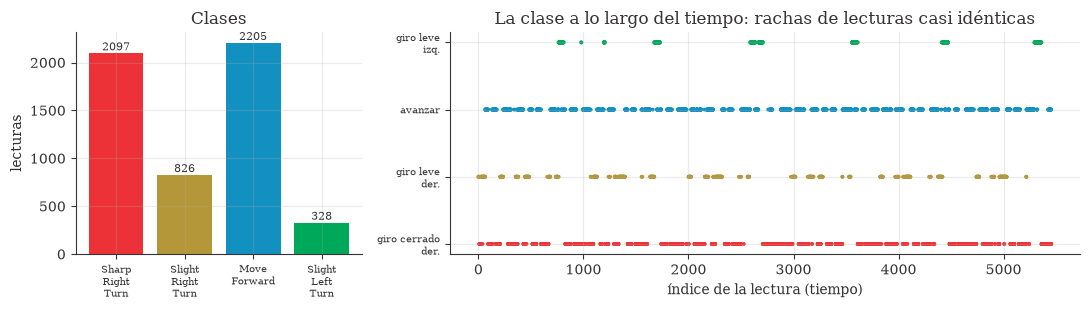

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw=dict(width_ratios=[1, 2.2]))
cuenta = np.bincount(y)
a1.bar(range(4), cuenta, color=COL_CLASE); a1.set_xticks(range(4)); a1.set_xticklabels([c.replace("-", "\n") for c in CLASES], fontsize=7)
for k, v in enumerate(cuenta): a1.text(k, v + 30, str(v), ha="center", fontsize=8)
a1.set_ylabel("lecturas"); a1.set_title("Clases")
a2.scatter(np.arange(N), y, c=[COL_CLASE[k] for k in y], s=3)
a2.set_yticks(range(4)); a2.set_yticklabels(["giro cerrado\nder.", "giro leve\nder.", "avanzar", "giro leve\nizq."], fontsize=7)
a2.set_xlabel("índice de la lectura (tiempo)"); a2.set_title("La clase a lo largo del tiempo: rachas de lecturas casi idénticas")
plt.tight_layout(); guardar_fig(fig, "f01_clases"); plt.show()

**Lectura del Paso 1.** Hay 5 456 lecturas en 4 clases desbalanceadas: *Move-Forward* 2 205, *Sharp-Right-Turn* 2 097, *Slight-Right-Turn* 826 y *Slight-Left-Turn* 328 (solo el 6 %). Por eso, además de la exactitud se reportan la **exactitud balanceada** y el **F1 macro**, que no dejan que la clase rara pase inadvertida. Tres rasgos de los datos condicionan el diseño: (1) hay **lecturas saturadas en 5,0** (91 en el sensor trasero), así que el rango útil de cada variable se mira sin ese tope; (2) hay **filas duplicadas** (50 en el archivo de 4 sensores y 279 en el de 2, porque con menos columnas se repiten más); (3) los datos son una **serie en el tiempo**: solo hay 395 cambios de clase en 5 455 pasos y una racha típica dura 6,5 lecturas, es decir, las lecturas vecinas son casi idénticas. Una partición muestra a muestra pondría vecinos casi iguales en entrenamiento y prueba y sobreestimaría la exactitud; de ahí la partición por **bloques de 100 lecturas consecutivas**.

## Paso 2. Análisis de datos: ¿qué funciones de pertenencia necesita cada sensor?
La nota del enunciado pide decidirlas mirando **histogramas**, **histogramas con clase** y la **nube de puntos**. Cada gráfica responde algo distinto:

| Gráfica | Pregunta |
|---|---|
| Histograma | ¿En qué rango viven los valores y dónde se concentran? (¿hay saturación?) |
| Histograma con clase | ¿Dónde cambia la clase dominante? Esos son los candidatos a **puntos de cruce** entre dos MF |
| Nube de puntos (2 sensores) | ¿La frontera entre clases depende de **una** variable o de una **combinación**? |

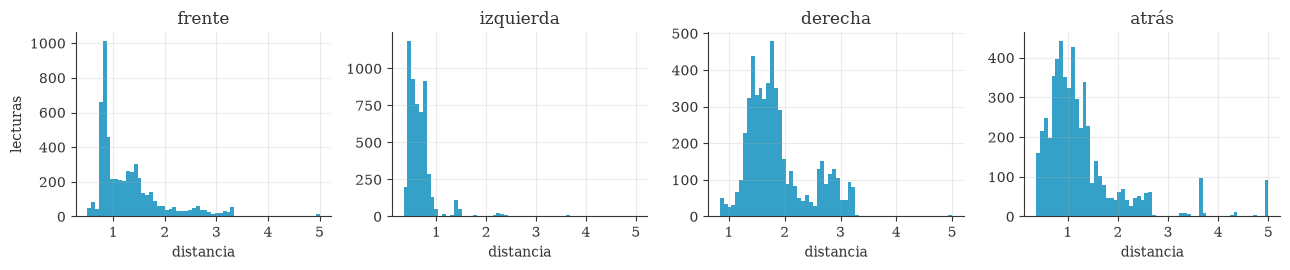

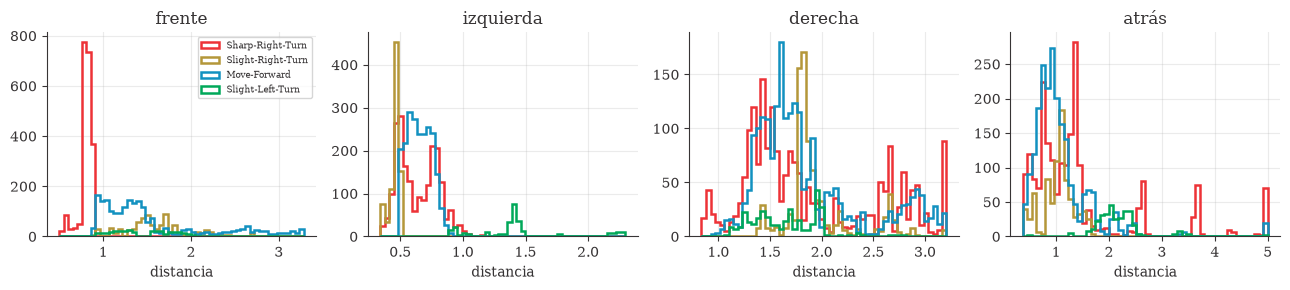

In [7]:
# 2.1 Histogramas de los 4 sensores
fig, ejes = plt.subplots(1, 4, figsize=(13, 2.8))
for j, ax in enumerate(ejes):
    ax.hist(X4[:, j], bins=60, color=UD["azul"], alpha=.85)
    ax.set_title(SENSORES[j]); ax.set_xlabel("distancia"); ax.set_ylabel("lecturas" if j == 0 else "")
plt.tight_layout(); guardar_fig(fig, "f02_histogramas"); plt.show()

# 2.2 Histogramas con clase (una curva por clase, mismas clases y colores en todas)
fig, ejes = plt.subplots(1, 4, figsize=(13, 3.0))
for j, ax in enumerate(ejes):
    lim = np.percentile(X4[:, j], 99)
    bins = np.linspace(X4[:, j].min(), lim, 55)
    for k in range(4):
        ax.hist(X4[y == k, j], bins=bins, histtype="step", lw=1.8, color=COL_CLASE[k], label=CLASES[k])
    ax.set_title(SENSORES[j]); ax.set_xlabel("distancia")
ejes[0].legend(fontsize=6.5, loc="upper right")
plt.tight_layout(); guardar_fig(fig, "f03_histogramas_clase"); plt.show()

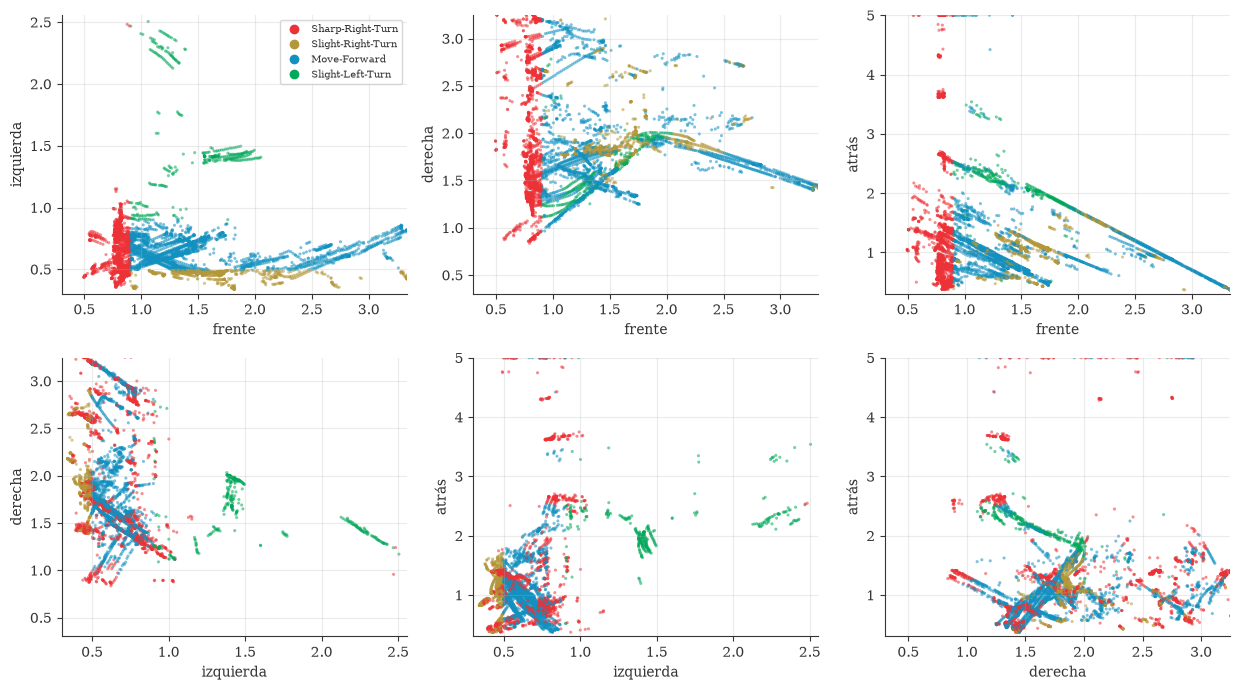

In [8]:
# 2.3 Nube de puntos: todos los pares de sensores, coloreados por clase
pares = [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)]
fig, ejes = plt.subplots(2, 3, figsize=(12.5, 7))
orden = np.random.default_rng(SEMILLA).permutation(N)
for ax, (a, b) in zip(ejes.ravel(), pares):
    ax.scatter(X4[orden, a], X4[orden, b], c=[COL_CLASE[k] for k in y[orden]], s=5, alpha=.55, linewidths=0)
    ax.set_xlabel(SENSORES[a]); ax.set_ylabel(SENSORES[b]); ax.set_xlim(0.3, np.percentile(X4[:, a], 99.5)); ax.set_ylim(0.3, np.percentile(X4[:, b], 99.5))
from matplotlib.lines import Line2D
ejes[0, 0].legend(handles=[Line2D([], [], marker="o", ls="", color=c, label=n) for c, n in zip(COL_CLASE, CLASES)], fontsize=7)
plt.tight_layout(); guardar_fig(fig, "f04_nube_pares"); plt.show()

**Lectura de las gráficas.**
- **Frente** (histograma con clase): *Sharp-Right-Turn* ocupa todo el pico de la izquierda y termina de forma abrupta en **0,9**; a la derecha de ese valor ya no aparece. Es un punto de cruce evidente entre "cerca" y "lejos".
- **Izquierda**: *Slight-Right-Turn* se acumula en un pico estrecho por debajo de **0,5**; *Move-Forward* ocupa 0,5 a 0,9 y *Slight-Left-Turn* queda aislado en valores altos (con un grupo en torno a 1,4). Pero el histograma **marginal** engaña: *Sharp-Right-Turn* se reparte por todos los valores de izquierda y tapa el corte de 0,9. Solo en el histograma **condicionado a frente > 0,9** (figura derecha de f05) se ven tres bloques separados con cortes en ≈ 0,5 y ≈ 0,9.
- **Nube frente–izquierda:** las clases forman **regiones rectangulares**: una franja vertical roja a la izquierda de frente = 0,9 y, a su derecha, tres franjas horizontales (dorada, azul, verde). Es decir, la frontera entre clases depende de **una variable a la vez**, no de una combinación: son umbrales, y eso hace que las MF trapezoidales con meseta sean la forma natural.
- **Derecha y atrás:** en sus histogramas con clase las cuatro curvas se superponen y en las nubes que las incluyen las clases están mezcladas; no hay un valor donde cambie la clase.

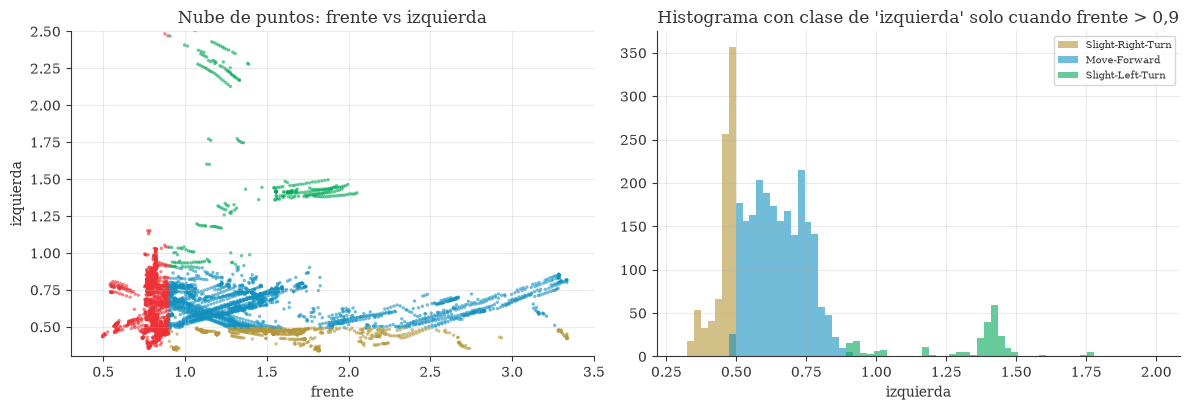

In [9]:
# 2.4 La nube que importa: frente vs izquierda, y el histograma de "izquierda" CONDICIONADO a frente > 0,9
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
a1.scatter(X4[orden, 0], X4[orden, 1], c=[COL_CLASE[k] for k in y[orden]], s=6, alpha=.6, linewidths=0)
a1.set_xlim(0.3, 3.5); a1.set_ylim(0.3, 2.5); a1.set_xlabel("frente"); a1.set_ylabel("izquierda"); a1.set_title("Nube de puntos: frente vs izquierda")
lejos = X4[:, 0] > 0.9
bins = np.linspace(0.3, 2.0, 70)
for k in range(1, 4):
    a2.hist(X4[lejos & (y == k), 1], bins=bins, histtype="stepfilled", alpha=.6, color=COL_CLASE[k], label=CLASES[k])
a2.set_xlabel("izquierda"); a2.set_title("Histograma con clase de 'izquierda' solo cuando frente > 0,9"); a2.legend(fontsize=7)
plt.tight_layout(); guardar_fig(fig, "f05_frente_izquierda"); plt.show()

In [10]:
# 2.5 Relevancia de cada sensor (todo calculado con los datos de entrenamiento definidos en el Paso 3)
tr, te = divisiones_por_bloques(N, tam_bloque=100, frac_prueba=0.3, semilla=SEMILLA)
F, _ = f_classif(X4[tr], y[tr])
MI = mutual_info_classif(X4[tr], y[tr], random_state=SEMILLA)
arbol_rel = DecisionTreeClassifier(max_leaf_nodes=12, random_state=SEMILLA).fit(X4[tr], y[tr])
rel = pd.DataFrame({"F de ANOVA": F, "información mutua": MI, "importancia en un árbol de 12 hojas": arbol_rel.feature_importances_}, index=SENSORES).round(3)
print(rel)
cortes = cortes_desde_arbol(X4[tr], y[tr])
print("\nCortes que usa un árbol pequeño (donde cambia la clase):", {SENSORES[j]: c.round(4).tolist() for j, c in cortes.items()})
verificar("Un árbol de pocas hojas solo usa frente e izquierda", set(cortes) == {0, 1}, "revise los datos")
verificar("Corte de frente = 0,9005", abs(cortes[0][0] - 0.9005) < 1e-3, "")
verificar("Cortes de izquierda = 0,4945 y 0,9015", np.allclose(cortes[1], [0.4945, 0.9015], atol=1e-3), "")

# ¿Bastan frente e izquierda? Un árbol de 4 hojas con solo esas dos variables frente a uno con las 4 (bloques de prueba)
for nombre, cols in (("solo frente e izquierda", [0, 1]), ("los 4 sensores", [0, 1, 2, 3])):
    a4 = DecisionTreeClassifier(max_leaf_nodes=4, random_state=SEMILLA).fit(X4[tr][:, cols], y[tr])
    print(f"Árbol de 4 hojas con {nombre}: exactitud en prueba = {a4.score(X4[te][:, cols], y[te]):.4f}")
a2h = DecisionTreeClassifier(max_leaf_nodes=4, random_state=SEMILLA).fit(X4[tr][:, :2], y[tr])
verificar("Con solo frente e izquierda, 4 reglas nítidas clasifican el 100 % de la prueba", a2h.score(X4[te][:, :2], y[te]) == 1.0, "")

           F de ANOVA  información mutua  importancia en un árbol de 12 hojas
frente        774.239              0.793                                0.556
izquierda    2714.577              0.577                                0.444
derecha         9.103              0.310                                0.000
atrás         119.270              0.329                                0.000

Cortes que usa un árbol pequeño (donde cambia la clase): {'frente': [0.9005], 'izquierda': [0.4945, 0.9015]}
[OK]      Un árbol de pocas hojas solo usa frente e izquierda
[OK]      Corte de frente = 0,9005
[OK]      Cortes de izquierda = 0,4945 y 0,9015
Árbol de 4 hojas con solo frente e izquierda: exactitud en prueba = 1.0000
Árbol de 4 hojas con los 4 sensores: exactitud en prueba = 1.0000
[OK]      Con solo frente e izquierda, 4 reglas nítidas clasifican el 100 % de la prueba


True

**Lectura del análisis.** La relevancia se mide de tres maneras y las tres ordenan igual a los dos primeros sensores. Un árbol pequeño solo usa **frente** (corte 0,9005) e **izquierda** (cortes 0,4945 y 0,9015) y deja **derecha** y **atrás** con importancia 0. La información mutua y la F de ANOVA de derecha y atrás no son cero porque cada sensor, por sí solo, guarda alguna relación con la clase (la geometría del recorrido), pero esa información ya está contenida en frente e izquierda. La comprobación decisiva es la última: **4 reglas nítidas con solo frente e izquierda clasifican el 100 % de la prueba**; añadir los otros dos sensores no mejora nada. Las clases del conjunto parecen venir de un controlador por umbrales sobre esos dos sensores (*frente ≤ 0,9 → giro cerrado; si no, izquierda ≤ 0,49 → giro leve a la derecha; ≤ 0,9 → avanzar; > 0,9 → giro leve a la izquierda*), cosa que el análisis recupera sin conocerlo.

**Decisión de MF:** frente 2 (cerca/lejos, cruce 0,9005), izquierda 3 (muy cerca/cerca/lejos, cruces 0,4945 y 0,9015). Para el modelo de 4 sensores, derecha y atrás llevan 2 MF cada una (cerca/lejos, cruce en la mediana) únicamente para cumplir con tener las 4 entradas; el análisis indica que podrían omitirse.

## Paso 3. Diseño de las funciones de pertenencia y construcción de los dos modelos
**Decisión de diseño.** Los puntos de cruce de las MF (donde dos etiquetas valen 0,5) se colocan en los cortes que muestra el análisis y cada MF es un
**trapecio con meseta**: vale 1 en su zona y baja a 0 en una franja de ancho $2w$ alrededor de cada corte. El parámetro $w$ es el **grado de
difusividad**: con $w=0$ el sistema es nítido y al crecer las etiquetas se traslapan más.

| Variable | MF | Etiquetas | Cruces |
|---|---|---|---|
| frente | 2 | cerca, lejos | 0,9005 |
| izquierda | 3 | muy cerca, cerca, lejos | 0,4945 y 0,9015 |
| derecha *(solo en el modelo de 4)* | 2 | cerca, lejos | mediana |
| atrás *(solo en el modelo de 4)* | 2 | cerca, lejos | mediana |

Número de reglas = producto de las MF por variable: **2 × 3 = 6** (2 sensores) y **2 × 3 × 2 × 2 = 24** (4 sensores), ambos por debajo del máximo de 100.
La base de reglas es **completa**: una regla por combinación, con la clase tomada de los datos de entrenamiento.

In [11]:
print("Entrenamiento:", len(tr), "lecturas | Prueba:", len(te), "lecturas (bloques completos de 100 lecturas consecutivas)")
print("Clases en entrenamiento:", np.bincount(y[tr]).tolist(), "| en prueba:", np.bincount(y[te]).tolist())
verificar("Entrenamiento y prueba no comparten bloques", len(set(tr // 100) & set(te // 100)) == 0, "")
verificar("Las 4 clases están en prueba", (np.bincount(y[te], minlength=4) > 0).all(), "")

ETIQ2 = [["cerca", "lejos"], ["muy cerca", "cerca", "lejos"]]
ETIQ4 = ETIQ2 + [["cerca", "lejos"], ["cerca", "lejos"]]

def particiones_modelo(w, n_sensores, idx=None):
    """Cortes del análisis (frente e izquierda) calculados SOLO con las lecturas `idx` (por defecto, el entrenamiento) y,
    para los sensores que el análisis descarta, un corte en la mediana."""
    idx = tr if idx is None else idx
    cor = cortes_desde_arbol(X4[idx], y[idx])
    P = [PartCortes(cor[0], w), PartCortes(cor[1], w)]
    if n_sensores == 4:
        P += [PartCortes([np.median(X4[idx, 2])], w), PartCortes([np.median(X4[idx, 3])], w)]
    return P

def metricas(yt, p):
    return dict(exactitud=accuracy_score(yt, p), exactitud_balanceada=balanced_accuracy_score(yt, p), f1_macro=f1_score(yt, p, average="macro"))

Entrenamiento: 3856 lecturas | Prueba: 1600 lecturas (bloques completos de 100 lecturas consecutivas)
Clases en entrenamiento: [1510, 562, 1591, 193] | en prueba: [587, 264, 614, 135]
[OK]      Entrenamiento y prueba no comparten bloques
[OK]      Las 4 clases están en prueba


In [12]:
# Elección de la difusividad w por validación cruzada en bloques SOLO con entrenamiento:
# la mayor w que pierde como mucho 0,2 puntos de exactitud balanceada frente al mejor valor
GRILLA_W = [0.0, 0.005, 0.01, 0.02, 0.05, 0.1]
def cv_w(X, n_sens):
    res = {}
    for w in GRILLA_W:
        sc = []
        for a, b in pliegues_por_bloques(len(tr), k=5, tam_bloque=100, semilla=0):
            clf = ClasificadorRejilla(particiones=particiones_modelo(w, n_sens, idx=tr[a])).fit(X[tr][a], y[tr][a], 4)
            sc.append(balanced_accuracy_score(y[tr][b], clf.predict(X[tr][b])))
        res[w] = (np.mean(sc), np.std(sc))
    mejor = max(v[0] for v in res.values())
    w_elegida = max(w for w, v in res.items() if v[0] >= mejor - 0.002)
    return res, w_elegida

cv2_res, W2 = cv_w(X2, 2)
cv4_res, W4 = cv_w(X4, 4)
print(f"{'w':>7} | {'2 sensores':>16} | {'4 sensores':>16}   (exactitud balanceada, CV en 5 pliegues por bloques)")
for w in GRILLA_W:
    print(f"{w:>7} | {cv2_res[w][0]:.4f} ± {cv2_res[w][1]:.4f} | {cv4_res[w][0]:.4f} ± {cv4_res[w][1]:.4f}")
print("w elegida: 2 sensores =", W2, "| 4 sensores =", W4)

      w |       2 sensores |       4 sensores   (exactitud balanceada, CV en 5 pliegues por bloques)
    0.0 | 0.9995 ± 0.0009 | 0.9995 ± 0.0009
  0.005 | 0.9995 ± 0.0009 | 1.0000 ± 0.0000
   0.01 | 0.9995 ± 0.0009 | 1.0000 ± 0.0000
   0.02 | 0.9984 ± 0.0010 | 0.9983 ± 0.0009
   0.05 | 0.9928 ± 0.0022 | 0.9879 ± 0.0040
    0.1 | 0.9762 ± 0.0047 | 0.9731 ± 0.0056
w elegida: 2 sensores = 0.02 | 4 sensores = 0.02


In [13]:
# Los dos modelos finales (con los datos de entrenamiento)
M2 = ClasificadorRejilla(particiones=particiones_modelo(W2, 2)).fit(X2[tr], y[tr], 4)
M4 = ClasificadorRejilla(particiones=particiones_modelo(W4, 4)).fit(X4[tr], y[tr], 4)
print(f"Modelo de 2 sensores: MF por variable = {M2.n_mf} -> {M2.n_reglas} reglas | w = {W2}")
print(f"Modelo de 4 sensores: MF por variable = {M4.n_mf} -> {M4.n_reglas} reglas | w = {W4}  ({int(M4.rellenada.sum())} completadas por vecindad)")
verificar("2 sensores: reglas = 2 x 3 = 6 (<= 100)", M2.n_reglas == 6 and M2.n_reglas <= 100, "")
verificar("4 sensores: reglas = 2 x 3 x 2 x 2 = 24 (<= 100)", M4.n_reglas == 24 and M4.n_reglas <= 100, "")
verificar("Cada variable tiene sus MF sumando 1 en cualquier punto (partición de Ruspini)",
          all(np.allclose(P.grados(np.linspace(0.3, 4, 50)).sum(axis=1), 1) for P in M4.particiones), "")

Modelo de 2 sensores: MF por variable = (2, 3) -> 6 reglas | w = 0.02
Modelo de 4 sensores: MF por variable = (2, 3, 2, 2) -> 24 reglas | w = 0.02  (2 completadas por vecindad)
[OK]      2 sensores: reglas = 2 x 3 = 6 (<= 100)
[OK]      4 sensores: reglas = 2 x 3 x 2 x 2 = 24 (<= 100)
[OK]      Cada variable tiene sus MF sumando 1 en cualquier punto (partición de Ruspini)


True

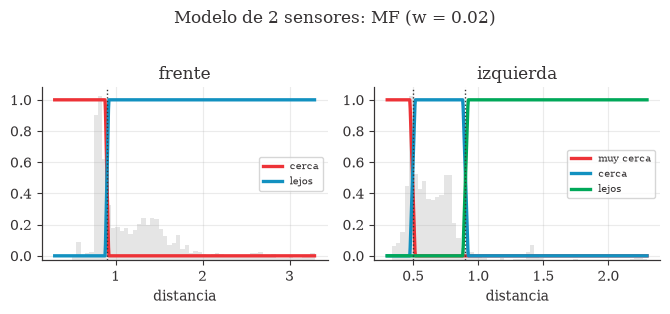

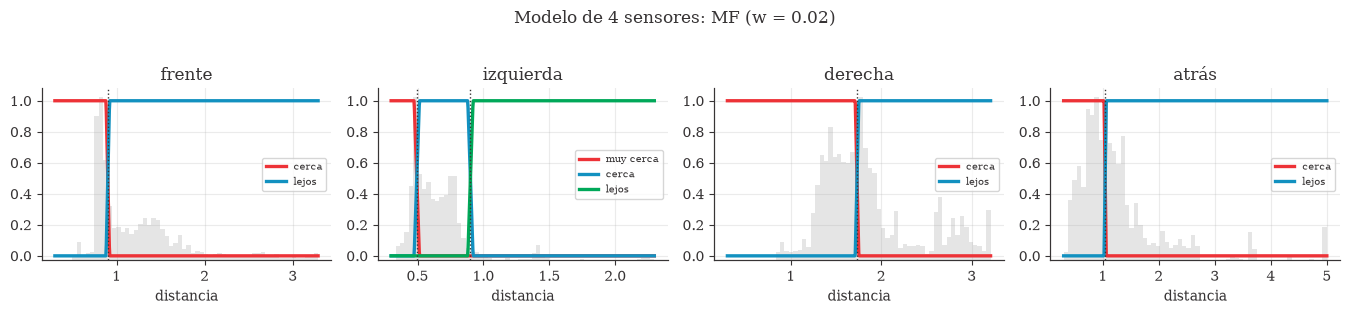

In [14]:
# 3.1 Las MF de cada variable sobre el histograma
def graficar_mfs_modelo(M, etiquetas, nombres, X, nombre_fig, titulo):
    F = len(M.particiones)
    fig, ejes = plt.subplots(1, F, figsize=(3.4 * F, 3.0))
    for j, (ax, P) in enumerate(zip(np.atleast_1d(ejes), M.particiones)):
        lo, hi = 0.3, np.percentile(X[:, j], 99)
        x = np.linspace(lo, hi, 600)
        h = ax.twinx(); h.hist(X[:, j], bins=60, range=(lo, hi), color=UD["plata"], alpha=.25); h.set_yticks([]); h.grid(False); h.spines["right"].set_visible(False)
        for (tipo, p), et, col in zip(P.mfs(lo, hi), etiquetas[j], [UD["rojo"], UD["azul"], UD["verde"]]):
            ax.plot(x, mf(tipo, p, x), lw=2.4, color=col, label=et)
        for t in P.cortes: ax.axvline(t, color=UD["sable"], ls=":", lw=1)
        ax.set_zorder(h.get_zorder() + 1); ax.patch.set_visible(False)
        ax.set_title(nombres[j]); ax.set_ylim(-0.03, 1.08); ax.set_xlabel("distancia"); ax.legend(fontsize=7, loc="center right")
    fig.suptitle(titulo, y=1.03); plt.tight_layout(); guardar_fig(fig, nombre_fig); plt.show()

graficar_mfs_modelo(M2, ETIQ2, SENSORES[:2], X4, "f06_mf_2sensores", f"Modelo de 2 sensores: MF (w = {W2})")
graficar_mfs_modelo(M4, ETIQ4, SENSORES, X4, "f07_mf_4sensores", f"Modelo de 4 sensores: MF (w = {W4})")

MODELO DE 2 SENSORES (6 reglas)
   SI frente es cerca Y izquierda es muy cerca ENTONCES Sharp-Right-Turn  (peso 0.98)
   SI frente es cerca Y izquierda es cerca ENTONCES Sharp-Right-Turn  (peso 0.99)
   SI frente es cerca Y izquierda es lejos ENTONCES Sharp-Right-Turn  (peso 0.94)
   SI frente es lejos Y izquierda es muy cerca ENTONCES Slight-Right-Turn  (peso 0.97)
   SI frente es lejos Y izquierda es cerca ENTONCES Move-Forward  (peso 0.90)
   SI frente es lejos Y izquierda es lejos ENTONCES Slight-Left-Turn  (peso 1.00)

MODELO DE 4 SENSORES (24 reglas; se muestran las 8 con más soporte)
   SI frente es lejos Y izquierda es lejos Y derecha es lejos Y atrás es lejos ENTONCES Slight-Left-Turn  (peso 1.00)
   SI frente es lejos Y izquierda es muy cerca Y derecha es lejos Y atrás es lejos ENTONCES Slight-Right-Turn  (peso 0.97)
   SI frente es lejos Y izquierda es cerca Y derecha es cerca Y atrás es cerca ENTONCES Move-Forward  (peso 0.97)
   SI frente es lejos Y izquierda es lejos Y de

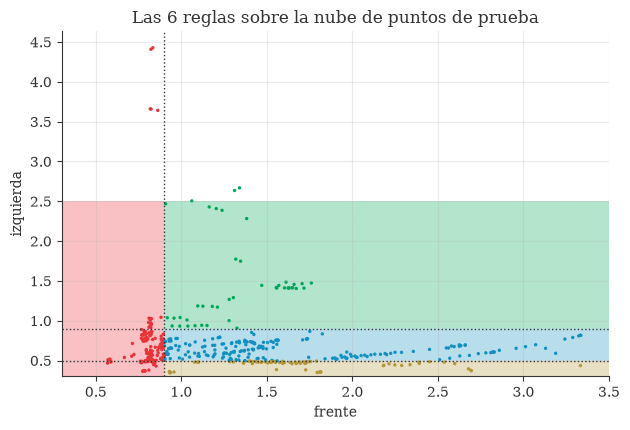

In [15]:
# 3.2 La base de reglas en lenguaje natural
print("MODELO DE 2 SENSORES (6 reglas)")
for r in M2.reglas_en_texto(SENSORES[:2], ETIQ2, CLASES, ordenar_por_soporte=False): print("  ", r)
print("\nMODELO DE 4 SENSORES (24 reglas; se muestran las 8 con más soporte)")
for r in M4.reglas_en_texto(SENSORES, ETIQ4, CLASES, max_reglas=8): print("  ", r)

# Mapa de reglas del modelo de 2 sensores: qué clase gana en cada punto del plano frente-izquierda
gx, gy = np.meshgrid(np.linspace(0.3, 3.5, 400), np.linspace(0.3, 2.5, 300))
Z = M2.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
fig, ax = plt.subplots(figsize=(6.4, 4.4))
ax.imshow(Z, origin="lower", extent=(0.3, 3.5, 0.3, 2.5), aspect="auto", cmap=ListedColormap(COL_CLASE), alpha=.30, vmin=0, vmax=3)
ax.scatter(X2[te][::3, 0], X2[te][::3, 1], c=[COL_CLASE[k] for k in y[te][::3]], s=6, linewidths=0)
for t in M2.particiones[0].cortes: ax.axvline(t, color=UD["sable"], lw=1, ls=":")
for t in M2.particiones[1].cortes: ax.axhline(t, color=UD["sable"], lw=1, ls=":")
ax.set_xlabel("frente"); ax.set_ylabel("izquierda"); ax.set_title("Las 6 reglas sobre la nube de puntos de prueba")
plt.tight_layout(); guardar_fig(fig, "f08_mapa_reglas"); plt.show()

**Lectura del Paso 3.** La validación cruzada por bloques elige la difusividad: con $w$ hasta 0,01 la exactitud balanceada es prácticamente la misma (≈ 99,95 a 100 %), a 0,02 baja ≈ 0,1 pts, a 0,05 baja ≈ 0,7 pts (2 sensores) y ≈ 1,2 pts (4 sensores) y a 0,1 ≈ 2,3 pts. La regla de selección (la mayor $w$ que pierde como máximo 0,2 pts) da **$w=0{,}02$** para ambos modelos: las etiquetas se traslapan en una franja de 0,04 alrededor de cada corte, lo que da un sistema genuinamente difuso sin sacrificar casi nada.

Los modelos quedan con **6 reglas** (2 × 3) y **24 reglas** (2 × 3 × 2 × 2), muy por debajo de las 100 permitidas. Las 6 reglas del modelo de 2 sensores se leen directamente: *frente cerca* implica *giro cerrado a la derecha* sea cual sea la izquierda (3 reglas con la misma salida); con *frente lejos* manda la izquierda. En el modelo de 4 sensores, 2 de las 24 combinaciones no aparecen en el entrenamiento y se completan con la regla más cercana de la rejilla, ponderando por la importancia de cada variable (así, cambiar una variable irrelevante "cuesta" poco).

## Paso 4. Evaluación honesta
Todas las cifras de esta sección son sobre los **bloques de prueba** (30 % de los bloques, que el diseño nunca vio). Se comparan los dos modelos con otros
diseños de MF que **no** usan el análisis (uniformes, por cuantiles y por Fuzzy C-Means), con el mismo límite de 100 reglas, y con modelos de referencia.

Modelo de 2 sensores : {'exactitud': 0.9981, 'exactitud_balanceada': 0.9988, 'f1_macro': 0.9988} | reglas: 6
Modelo de 4 sensores : {'exactitud': 0.995, 'exactitud_balanceada': 0.9939, 'f1_macro': 0.9945} | reglas: 24
[OK]      2 sensores: exactitud en prueba >= 99 %
[OK]      4 sensores: exactitud en prueba >= 99 %


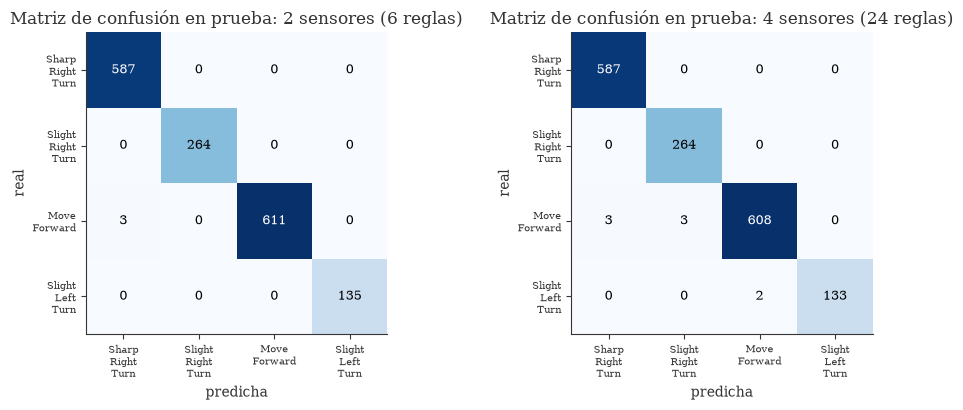

2 sensores: 3 errores de 1600; distancia al corte más cercano: máx. 0.0005
[OK]      2 sensores: todos los errores están a menos de 0,01 de un corte
4 sensores: 8 errores de 1600; distancia al corte más cercano: máx. 0.0055
[OK]      4 sensores: todos los errores están a menos de 0,01 de un corte


In [16]:
def evaluar_modelo(M, X):
    p = M.predict(X[te]); return metricas(y[te], p), p

met2, p2 = evaluar_modelo(M2, X2)
met4, p4 = evaluar_modelo(M4, X4)
print("Modelo de 2 sensores :", {k: round(v, 4) for k, v in met2.items()}, "| reglas:", M2.n_reglas)
print("Modelo de 4 sensores :", {k: round(v, 4) for k, v in met4.items()}, "| reglas:", M4.n_reglas)
verificar("2 sensores: exactitud en prueba >= 99 %", met2["exactitud"] >= 0.99, "revise las MF")
verificar("4 sensores: exactitud en prueba >= 99 %", met4["exactitud"] >= 0.99, "revise las MF")

fig, ejes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, p, tit, M in ((ejes[0], p2, f"2 sensores ({M2.n_reglas} reglas)", M2), (ejes[1], p4, f"4 sensores ({M4.n_reglas} reglas)", M4)):
    cm = confusion_matrix(y[te], p, labels=range(4)); ax.imshow(cm, cmap="Blues"); ax.grid(False)
    for i in range(4):
        for j in range(4): ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=9)
    ax.set_xticks(range(4)); ax.set_yticks(range(4)); ax.set_xticklabels([c.replace("-", "\n") for c in CLASES], fontsize=7); ax.set_yticklabels([c.replace("-", "\n") for c in CLASES], fontsize=7)
    ax.set_xlabel("predicha"); ax.set_ylabel("real"); ax.set_title(f"Matriz de confusión en prueba: {tit}")
plt.tight_layout(); guardar_fig(fig, "f09_matrices_confusion"); plt.show()

# ¿Dónde están los errores? Distancia de cada lectura mal clasificada al corte más cercano (en frente o izquierda)
def distancia_a_corte(x):
    return min(min(abs(x[0] - c) for c in M2.particiones[0].cortes), min(abs(x[1] - c) for c in M2.particiones[1].cortes))
for nombre, p_, X in (("2 sensores", p2, X2), ("4 sensores", p4, X4)):
    mal = np.where(p_ != y[te])[0]
    dist = [distancia_a_corte(X[te][i]) for i in mal]
    print(f"{nombre}: {len(mal)} errores de {len(te)}; distancia al corte más cercano: máx. {max(dist):.4f}" if len(mal) else f"{nombre}: sin errores")
    verificar(f"{nombre}: todos los errores están a menos de 0,01 de un corte", all(d < 0.01 for d in dist), "hay errores lejos de los cortes")

In [17]:
# 4.1 ¿Y si no se hace el análisis? Diseños automáticos con el mismo límite de 100 reglas
# Para cada método se elige el número de MF por variable por validación cruzada en bloques (solo con entrenamiento).
def buscar_diseno(X, metodo, rango_mf, limite=100):
    F = X.shape[1]; mejor = None; todos = []
    for n_mf in itertools.product(rango_mf, repeat=F):
        if np.prod(n_mf) > limite: continue
        sc = []
        for a, b in pliegues_por_bloques(len(tr), k=5, tam_bloque=100, semilla=0):
            clf = ClasificadorRejilla(n_mf, metodo).fit(X[tr][a], y[tr][a], 4)
            sc.append(balanced_accuracy_score(y[tr][b], clf.predict(X[tr][b])))
        todos.append((int(np.prod(n_mf)), float(np.mean(sc)), n_mf))
        if mejor is None or np.mean(sc) > mejor[0]: mejor = (float(np.mean(sc)), n_mf)
    return mejor, todos

filas, curvas = [], {}
for nombre, X, rango in (("2 sensores", X2, range(2, 11)), ("4 sensores", X4, range(2, 6))):
    for metodo in ("uniforme", "cuantiles", "fcm"):
        (cv, n_mf), todos = buscar_diseno(X, metodo, rango)
        clf = ClasificadorRejilla(n_mf, metodo).fit(X[tr], y[tr], 4); m = metricas(y[te], clf.predict(X[te]))
        filas.append(dict(modelo=nombre, diseño=f"{metodo} (automático)", mf=str(n_mf), reglas=clf.n_reglas, cv_balanceada=cv, **m))
        curvas[(nombre, metodo)] = todos
    M, met = (M2, met2) if nombre == "2 sensores" else (M4, met4)
    filas.append(dict(modelo=nombre, diseño="cortes del análisis (propuesto)", mf=str(M.n_mf), reglas=M.n_reglas, cv_balanceada=(cv2_res if nombre == "2 sensores" else cv4_res)[W2 if nombre == "2 sensores" else W4][0], **met))
tabla_disenos = pd.DataFrame(filas)
print(tabla_disenos.round(4).to_string(index=False))

    modelo                          diseño           mf  reglas  cv_balanceada  exactitud  exactitud_balanceada  f1_macro
2 sensores           uniforme (automático)      (6, 10)      60         0.9538     0.9138                0.9423    0.9083
2 sensores          cuantiles (automático)       (6, 8)      48         0.9670     0.9444                0.9626    0.9479
2 sensores                fcm (automático)      (8, 10)      80         0.9557     0.9606                0.9729    0.9519
2 sensores cortes del análisis (propuesto)       (2, 3)       6         0.9984     0.9981                0.9988    0.9988
4 sensores           uniforme (automático) (5, 5, 2, 2)     100         0.8671     0.7869                0.8080    0.7799
4 sensores          cuantiles (automático) (3, 4, 3, 2)      72         0.9537     0.9525                0.9633    0.9552
4 sensores                fcm (automático) (5, 5, 2, 2)     100         0.9004     0.8356                0.8305    0.8228
4 sensores cortes del an

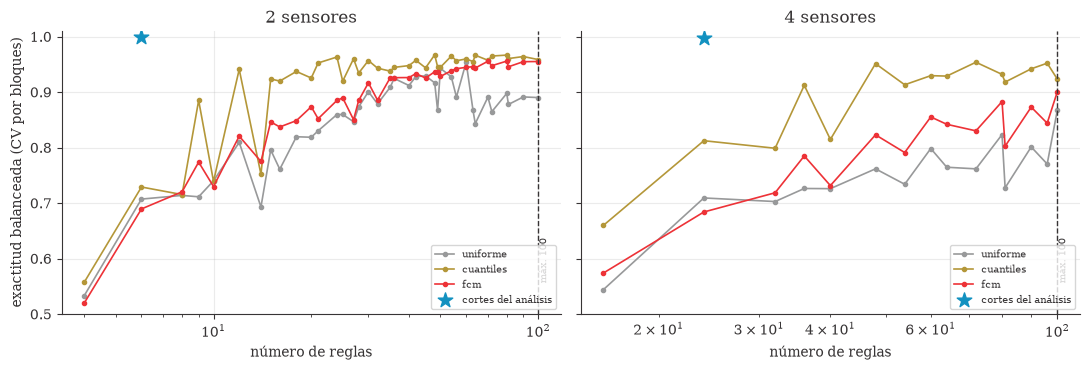

In [18]:
# Figura: exactitud balanceada (validación cruzada) frente al número de reglas, mejor configuración para cada cantidad de reglas
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, nombre, M in ((ejes[0], "2 sensores", M2), (ejes[1], "4 sensores", M4)):
    for metodo, col in (("uniforme", UD["plata"]), ("cuantiles", UD["dorado"]), ("fcm", UD["rojo"])):
        todos = curvas[(nombre, metodo)]
        mejor_por_n = {}
        for nr, sc, _ in todos: mejor_por_n[nr] = max(sc, mejor_por_n.get(nr, 0))
        xs = sorted(mejor_por_n); ax.plot(xs, [mejor_por_n[x] for x in xs], "o-", ms=3, lw=1.2, color=col, label=metodo)
    fila = tabla_disenos[(tabla_disenos.modelo == nombre) & tabla_disenos.diseño.str.startswith("cortes")].iloc[0]
    ax.scatter([M.n_reglas], [fila.cv_balanceada], s=120, marker="*", color=UD["azul"], zorder=5, label="cortes del análisis")
    ax.axvline(100, color=UD["sable"], ls="--", lw=1); ax.text(100, 0.55, " máx. 100", rotation=90, va="bottom", fontsize=7)
    ax.set_xscale("log"); ax.set_xlabel("número de reglas"); ax.set_title(nombre); ax.legend(fontsize=7, loc="lower right")
ejes[0].set_ylabel("exactitud balanceada (CV por bloques)"); ejes[0].set_ylim(0.5, 1.01)
plt.tight_layout(); guardar_fig(fig, "f10_reglas_vs_exactitud"); plt.show()

partición                                  muestra a muestra  por bloques  \
modelo     método                                                           
2 sensores difuso con cortes del análisis             0.9982       0.9981   
           difuso cuantiles                           0.9652       0.9444   
           difuso uniforme                            0.9181       0.9138   
           kNN (k = 15)                               0.9695       0.9500   
           árbol (60 hojas)                           1.0000       1.0000   
4 sensores difuso con cortes del análisis             0.9963       0.9950   
           difuso cuantiles                           0.9395       0.9525   
           difuso uniforme                            0.8149       0.7869   
           kNN (k = 15)                               0.9395       0.8562   
           árbol (60 hojas)                           1.0000       1.0000   

partición                                  inflación (pts)  
modelo     mét

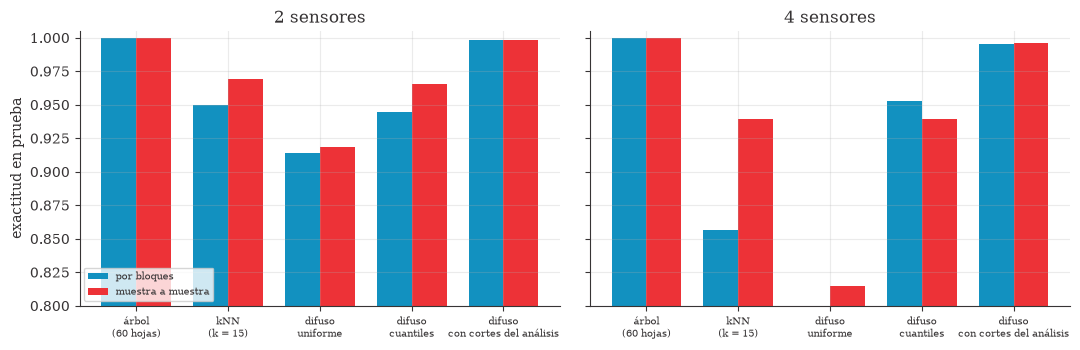

In [19]:
# 4.2 Modelos de referencia y el efecto de la partición muestra a muestra (fuga entre lecturas vecinas)
def comparar_particiones(X, M_mf, nombre):
    out = []
    rng_tr, rng_te = train_test_split(np.arange(N), test_size=0.3, stratify=y, random_state=SEMILLA)       # muestra a muestra
    for etiqueta, a, b in (("por bloques", tr, te), ("muestra a muestra", rng_tr, rng_te)):
        modelos = {"árbol (60 hojas)": DecisionTreeClassifier(max_leaf_nodes=60, random_state=SEMILLA),
                   "kNN (k = 15)": KNeighborsClassifier(15)}
        for n, mod in modelos.items():
            out.append((nombre, etiqueta, n, accuracy_score(y[b], mod.fit(X[a], y[a]).predict(X[b]))))
        for metodo in ("uniforme", "cuantiles"):
            clf = ClasificadorRejilla(M_mf[metodo], metodo).fit(X[a], y[a], 4); out.append((nombre, etiqueta, f"difuso {metodo}", accuracy_score(y[b], clf.predict(X[b]))))
        clf = ClasificadorRejilla(particiones=particiones_modelo(W2 if X.shape[1] == 2 else W4, X.shape[1], idx=a)).fit(X[a], y[a], 4)
        out.append((nombre, etiqueta, "difuso con cortes del análisis", accuracy_score(y[b], clf.predict(X[b]))))
    return out

mf_auto2 = {m: eval(tabla_disenos[(tabla_disenos.modelo == "2 sensores") & (tabla_disenos.diseño == f"{m} (automático)")].mf.iloc[0]) for m in ("uniforme", "cuantiles")}
mf_auto4 = {m: eval(tabla_disenos[(tabla_disenos.modelo == "4 sensores") & (tabla_disenos.diseño == f"{m} (automático)")].mf.iloc[0]) for m in ("uniforme", "cuantiles")}
comp = pd.DataFrame(comparar_particiones(X2, mf_auto2, "2 sensores") + comparar_particiones(X4, mf_auto4, "4 sensores"), columns=["modelo", "partición", "método", "exactitud"])
pivote = comp.pivot_table(index=["modelo", "método"], columns="partición", values="exactitud").round(4)
pivote["inflación (pts)"] = ((pivote["muestra a muestra"] - pivote["por bloques"]) * 100).round(2)
print(pivote)

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, nombre in zip(ejes, ("2 sensores", "4 sensores")):
    sub = comp[comp.modelo == nombre]; metodos = list(dict.fromkeys(sub["método"])); xs = np.arange(len(metodos))
    for k, (part, col) in enumerate((("por bloques", UD["azul"]), ("muestra a muestra", UD["rojo"]))):
        v = [sub[(sub["método"] == m) & (sub["partición"] == part)].exactitud.iloc[0] for m in metodos]
        ax.bar(xs + (k - .5) * .38, v, .38, color=col, label=part)
    ax.set_xticks(xs); ax.set_xticklabels([m.replace(" ", "\n", 1) for m in metodos], fontsize=7); ax.set_title(nombre); ax.set_ylim(0.8, 1.005)
ejes[0].set_ylabel("exactitud en prueba"); ejes[0].legend(fontsize=7, loc="lower left")
plt.tight_layout(); guardar_fig(fig, "f11_fuga_particion"); plt.show()

**Lectura del Paso 4.** En los bloques de prueba, el modelo de **2 sensores** (6 reglas) acierta **99,81 %** (exactitud balanceada 99,88 %) y el de **4 sensores** (24 reglas) **99,50 %** (99,39 %). Los errores (3 y 8 lecturas de 1 600) están **a menos de 0,002 de un corte** en la variable que decide (por ejemplo, frente = 0,901 cuando el corte es 0,9005), justo donde las dos etiquetas valen casi lo mismo: es el costo esperado de una transición suave. Que el de 4 sensores sea ligeramente peor que el de 2 no es casualidad: sus dos variables extra no aportan información y solo multiplican las reglas por 4, repartiendo las mismas lecturas en celdas más pequeñas.

**El análisis sí importa.** Con el mismo límite de 100 reglas, los diseños **automáticos** (MF uniformes, por cuantiles o por Fuzzy C-Means, con el número de MF elegido por validación cruzada) logran entre 91 y 96 % con 2 sensores y entre 79 y 95 % con 4 (los uniformes y los de FCM empeoran al repartir MF por sensores irrelevantes), usando de 48 a 100 reglas. El diseño con cortes del análisis llega a más de 99 % con **6 y 24** reglas. Menos reglas, más exactitud y reglas que se pueden leer.

**Cuidado con la partición.** Con la partición muestra a muestra, kNN pasa de 85,6 % a 94,0 % en el modelo de 4 sensores (**+8,3 pts** de pura fuga entre lecturas vecinas) y los diseños automáticos por cuantiles ganan hasta 2 pts. Los modelos con cortes del análisis casi no cambian (+0,01 y +0,13 pts) porque no memorizan: aprenden umbrales. El árbol de decisión llega a 100 % con cualquiera de las dos particiones, lo que confirma que la regla de decisión es nítida.

## Paso 5. Sensibilidad a la difusividad y variante Mamdani
¿Cuánta "borrosidad" tolera el modelo? Se varía $w$ y se mide la exactitud en prueba con dos formas de producir la salida:
**regla ganadora** (la clase de la regla más fuerte) y **Mamdani con centroide**, donde las clases se ordenan de giro cerrado a la derecha (0) a giro leve a la
izquierda (3) y la salida es un número "giro" en [−0,5; 3,5] que se redondea.

         ganadora               mamdani           
modelo 2 sensores 4 sensores 2 sensores 4 sensores
w                                                 
0.000      1.0000     1.0000     1.0000     1.0000
0.005      1.0000     0.9994     0.9781     0.9781
0.010      1.0000     0.9981     0.9594     0.9588
0.020      0.9981     0.9950     0.9450     0.9425
0.050      0.9875     0.9819     0.8919     0.8900
0.100      0.9675     0.9600     0.8194     0.8206
0.200      0.9262     0.9100     0.5819     0.5788


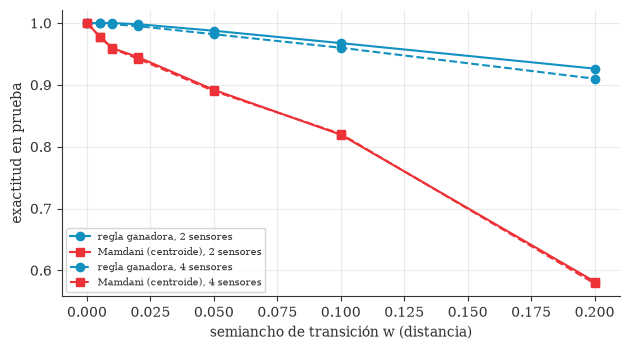

In [20]:
Ws = [0.0, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2]
sens = []
for w in Ws:
    for nombre, X, n_s in (("2 sensores", X2, 2), ("4 sensores", X4, 4)):
        M = ClasificadorRejilla(particiones=particiones_modelo(w, n_s)).fit(X[tr], y[tr], 4)
        giro, cl = mamdani_giro(M, X[te])
        sens.append(dict(w=w, modelo=nombre, ganadora=accuracy_score(y[te], M.predict(X[te])), mamdani=accuracy_score(y[te], cl)))
sens = pd.DataFrame(sens)
print(sens.pivot(index="w", columns="modelo", values=["ganadora", "mamdani"]).round(4))

fig, ax = plt.subplots(figsize=(6.4, 3.6))
for (nombre, ls) in (("2 sensores", "-"), ("4 sensores", "--")):
    s = sens[sens.modelo == nombre]
    ax.plot(s.w, s.ganadora, ls, marker="o", color=UD["azul"], label=f"regla ganadora, {nombre}")
    ax.plot(s.w, s.mamdani, ls, marker="s", color=UD["rojo"], label=f"Mamdani (centroide), {nombre}")
ax.set_xlabel("semiancho de transición w (distancia)"); ax.set_ylabel("exactitud en prueba"); ax.legend(fontsize=7)
plt.tight_layout(); guardar_fig(fig, "f12_sensibilidad_w"); plt.show()

In [21]:
# Comprobación cruzada con scikit-fuzzy: el modelo de 2 sensores como sistema Mamdani (Y = mínimo, centroide) debe dar el mismo "giro"
try:
    import skfuzzy as fuzz
    from skfuzzy import control as ctrl
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-fuzzy"], check=False)
    import skfuzzy as fuzz
    from skfuzzy import control as ctrl

W_CHECK = 0.02
Mc = ClasificadorRejilla(particiones=particiones_modelo(W_CHECK, 2), t_norma="min", usar_peso=False).fit(X2[tr], y[tr], 4)
uni = np.linspace(0.3, 5.0, 4701)          # paso de 0,001: mucho menor que el ancho de la transición (2w = 0,04)
fr = ctrl.Antecedent(uni, "frente"); iz = ctrl.Antecedent(uni, "izquierda"); gi = ctrl.Consequent(np.linspace(-0.5, 3.5, 201), "giro")
for A, P, et in ((fr, Mc.particiones[0], ETIQ2[0]), (iz, Mc.particiones[1], ETIQ2[1])):
    for (tipo, p), e in zip(P.mfs(0.3, 5.0), et):
        A[e] = fuzz.trapmf(A.universe, list(p))
for c, nombre_c in enumerate(CLASES):
    gi[nombre_c] = fuzz.trimf(gi.universe, [c - 1, c, c + 1])
reglas_sk = [ctrl.Rule(fr[ETIQ2[0][r[0]]] & iz[ETIQ2[1][r[1]]], gi[CLASES[c]]) for r, c in zip(Mc.reglas, Mc.clase_regla)]
sim = ctrl.ControlSystemSimulation(ctrl.ControlSystem(reglas_sk))
rng = np.random.default_rng(SEMILLA); idx = rng.choice(te, 150, replace=False)
giro_sk = []
for i in idx:
    sim.input["frente"], sim.input["izquierda"] = float(np.clip(X2[i, 0], 0.3, 5)), float(np.clip(X2[i, 1], 0.3, 5)); sim.compute(); giro_sk.append(sim.output["giro"])
giro_nuestro, _ = mamdani_giro(Mc, X2[idx])
dif = np.nanmax(np.abs(np.array(giro_sk) - giro_nuestro))
print(f"Diferencia máxima entre nuestro Mamdani y scikit-fuzzy en 150 puntos: {dif:.4f}")
verificar("Nuestro Mamdani coincide con scikit-fuzzy (diferencia < 0,02 por la discretización)", dif < 0.02, "")

Diferencia máxima entre nuestro Mamdani y scikit-fuzzy en 150 puntos: 0.0059
[OK]      Nuestro Mamdani coincide con scikit-fuzzy (diferencia < 0,02 por la discretización)


np.True_

**Lectura del Paso 5.** Con **regla ganadora** la exactitud cae poco y de forma gradual al aumentar la difusividad: 100 % con $w\le0{,}01$ (2 sensores), 98,8 % con 0,05 y 92,6 % con 0,2 (allí las etiquetas ya se traslapan en una franja de 0,4, comparable con el ancho de la clase *Move-Forward*). Con **Mamdani y centroide** la caída es mucho más rápida: 97,8 % con $w=0{,}005$ y 58 % con $w=0{,}2$. La razón es que las clases son **categorías**, y el centroide mezcla las salidas de reglas vecinas en un número intermedio que, al redondear, puede caer en una tercera clase (por ejemplo, entre *Sharp-Right-Turn* y *Slight-Left-Turn*, que no son vecinas). Para **clasificar**, la regla ganadora es la opción correcta; la salida Mamdani tiene sentido como **señal de dirección continua** (la superficie del Paso 6), no como clase.

La comprobación con `scikit-fuzzy` valida la implementación: nuestro Mamdani y el de la librería (con Y = mínimo y la misma base de 6 reglas) difieren en menos de 0,02 sobre 150 puntos.

## Paso 6. Superficie de control del modelo de 2 sensores
Como en la app *Fuzzy Logic Designer* (vista *Surface*): la salida "giro" del sistema Mamdani para cada par (frente, izquierda).

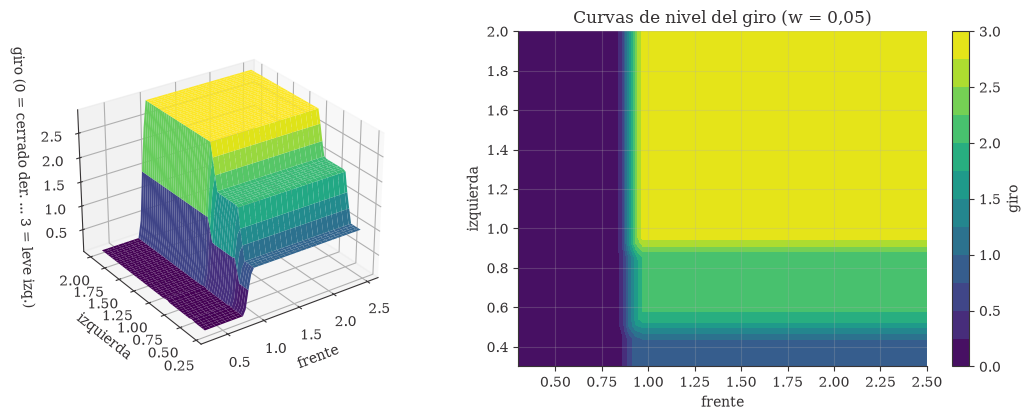

In [22]:
gx, gy = np.meshgrid(np.linspace(0.3, 2.5, 60), np.linspace(0.3, 2.0, 50))
M_s = ClasificadorRejilla(particiones=particiones_modelo(0.05, 2)).fit(X2[tr], y[tr], 4)
giro_s, _ = mamdani_giro(M_s, np.c_[gx.ravel(), gy.ravel()]); G = giro_s.reshape(gx.shape)
fig = plt.figure(figsize=(11, 4.3))
a1 = fig.add_subplot(1, 2, 1, projection="3d"); a1.plot_surface(gx, gy, G, cmap="viridis", linewidth=0, antialiased=True)
a1.set_xlabel("frente"); a1.set_ylabel("izquierda"); a1.set_zlabel("giro (0 = cerrado der. ... 3 = leve izq.)"); a1.view_init(28, -125)
a2 = fig.add_subplot(1, 2, 2); cs = a2.contourf(gx, gy, G, levels=np.linspace(0, 3, 13), cmap="viridis"); fig.colorbar(cs, ax=a2, label="giro")
a2.set_xlabel("frente"); a2.set_ylabel("izquierda"); a2.set_title("Curvas de nivel del giro (w = 0,05)")
plt.tight_layout(); guardar_fig(fig, "f13_superficie"); plt.show()

## Paso 7. Guardar los modelos y resumen de resultados

In [23]:
def exportar_modelo(M, etiquetas, nombres, w, X):
    return dict(
        sensores=nombres, mf_por_variable=list(M.n_mf), n_reglas=int(M.n_reglas), w=w,
        cortes=[P.cortes.round(4).tolist() for P in M.particiones],
        etiquetas=etiquetas,
        mfs=[[(t, [round(float(v), 4) for v in p]) for t, p in P.mfs(0.3, 5.0)] for P in M.particiones],
        reglas=[dict(si=[etiquetas[j][int(i)] for j, i in enumerate(r)], clase=CLASES[int(c)], peso=round(float(p), 3), soporte=round(float(s), 3))
                for r, c, p, s in zip(M.reglas, M.clase_regla, M.peso_regla, M.soporte)])

resumen = dict(
    n_lecturas=int(N), clases=CLASES, conteo_clases=np.bincount(y).tolist(), cortes_arbol={SENSORES[j]: c.round(4).tolist() for j, c in cortes.items()},
    relevancia=rel.to_dict(), n_train=int(len(tr)), n_test=int(len(te)),
    modelo2=dict(**exportar_modelo(M2, ETIQ2, SENSORES[:2], W2, X2), prueba=met2), modelo4=dict(**exportar_modelo(M4, ETIQ4, SENSORES, W4, X4), prueba=met4),
    disenos=tabla_disenos.round(4).to_dict(orient="records"), fuga=pivote.reset_index().round(4).to_dict(orient="records"),
    sensibilidad=sens.round(4).to_dict(orient="records"), cv_w={"2": {str(k): v[0] for k, v in cv2_res.items()}, "4": {str(k): v[0] for k, v in cv4_res.items()}},
    duplicados=dict(sensores4=int(d4.duplicated().sum()), sensores2=int(d2.duplicated().sum())), racha_mediana=float(np.median(rachas)), cambios_clase=int(len(rachas) - 1),
    matriz_2=confusion_matrix(y[te], p2).tolist(), matriz_4=confusion_matrix(y[te], p4).tolist())
with open(f"{CARPETA_RES}/resumen_adicional.json", "w", encoding="utf-8") as f:
    json.dump(resumen, f, ensure_ascii=False, indent=1)
pd.DataFrame(resumen["modelo2"]["reglas"]).to_csv(f"{CARPETA_RES}/reglas_2_sensores.csv", index=False)
pd.DataFrame(resumen["modelo4"]["reglas"]).to_csv(f"{CARPETA_RES}/reglas_4_sensores.csv", index=False)
np.savez_compressed(f"{CARPETA_RES}/datos_robot.npz", X4=X4, y=y, tr=tr, te=te)
print("Guardado:", sorted(os.listdir(CARPETA_RES)))
verificar("Los dos modelos respetan el máximo de 100 reglas", max(M2.n_reglas, M4.n_reglas) <= 100, "")

Guardado: ['datos_robot.npz', 'reglas_2_sensores.csv', 'reglas_4_sensores.csv', 'reglas_fisSub.csv', 'resumen_adicional.json', 'resumen_propuesto.json']
[OK]      Los dos modelos respetan el máximo de 100 reglas


True

## Conclusiones
1. **El análisis de datos define las funciones de pertenencia.** Los histogramas con clase y la nube frente–izquierda muestran que las clases separan por umbrales sobre **dos** sensores (frente en 0,9; izquierda en 0,49 y 0,9); derecha y atrás no aportan.
2. **Modelo de 2 sensores:** 2 × 3 = **6 reglas**, 99,81 % de exactitud y 99,88 % de exactitud balanceada en bloques de prueba. **Modelo de 4 sensores:** 2 × 3 × 2 × 2 = **24 reglas**, 99,50 % y 99,39 %. Ambos respetan el máximo de 100 reglas con amplio margen.
3. **Más reglas no es mejor:** los diseños automáticos con hasta 100 reglas rinden entre 79 y 96 %. La calidad la da dónde se ponen los cruces de las MF, no cuántas MF hay.
4. **La difusividad tiene un costo medible:** hasta $w=0{,}01$ no se pierde nada; con $w=0{,}02$ (la elegida) se pierden 0,2 a 0,5 pts; con $w=0{,}2$ se pierde ≈ 7 pts. Para clasificar conviene la regla ganadora; el centroide de Mamdani es mejor como salida de control continua.
5. **Cuidado con series de tiempo:** la partición muestra a muestra infla kNN hasta 8 pts; la evaluación por bloques es la honesta.
6. **Limitaciones:** los nombres de los sensores se toman del dataset original (UCI) porque los CSV no traen encabezado; la regla de decisión parece venir de un controlador por umbrales, por lo que estos resultados no se extrapolan a otro robot o entorno sin repetir el análisis; una sola partición por bloques (semilla 42) para la prueba.